# El-Sharnouby Group End-to-End Forecasting and Risk Analysis

## 1. Title and Project Objective

This notebook is the final analytical story for the El-Sharnouby Group internship project. It summarizes the accepted work from raw data audit through final decision outputs, using only the provided project data and the accepted Phase 1-10 outputs.

The objective is to support finished-goods forecasting and cross-functional planning at the Product_ID x Location_ID grain. The notebook documents the evidence behind demand behavior, forecast validation, inventory exposure, gross material requirements, historical procurement risk, historical production risk, and the final Phase 9 decision layer.

This is a presentation and reviewer notebook. It does not retrain models, regenerate forecasts, recalculate replenishment, create new risk logic, or infer unavailable business facts.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except Exception:
    display = print

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "outputs").exists() and (PROJECT_ROOT.parent / "outputs").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
OUTPUTS = PROJECT_ROOT / "outputs"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (9, 4.8)
plt.rcParams["axes.grid"] = True


def read_csv(relative_path):
    path = PROJECT_ROOT / relative_path
    if not path.exists():
        raise FileNotFoundError(f"Missing expected accepted project file: {relative_path}")
    return pd.read_csv(path)


def show_table(df, columns=None, n=10):
    view = df.copy()
    if columns is not None:
        view = view[[col for col in columns if col in view.columns]]
    display(view.head(n))


def simple_bar(labels, values, title, ylabel="Rows", color="#2563eb"):
    fig, ax = plt.subplots()
    ax.bar(labels, values, color=color)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    plt.show()


def horizontal_bar(df, label_col, value_col, title, n=12, color="#2563eb"):
    view = df[[label_col, value_col]].sort_values(value_col, ascending=False).head(n).sort_values(value_col)
    fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(view))))
    ax.barh(view[label_col].astype(str), view[value_col], color=color)
    ax.set_title(title)
    ax.set_xlabel(value_col)
    plt.tight_layout()
    plt.show()


## 2. Executive Summary

The business problem is to connect demand forecasting, finished-goods inventory exposure, material requirements, procurement evidence, production evidence, and final management prioritization without fabricating unavailable operational data.

Accepted final approach:

- Forecasting grain: Product_ID x Location_ID.
- Future forecast origin: 2026-09-30.
- Forecast windows: 30, 60, and 90 days from 2026-10-01.
- Final policy: guarded_hybrid, with baseline fallback when advanced models do not show robust validation evidence.
- Final decision layer: accepted Phase 9 outputs, not a new score created in this notebook.

Strongest key findings:

- Sales history contains 180,000 rows from 2023-10-01 to 2026-09-30.
- The accepted daily demand panel contains 193,435 rows for 177 Product x Location series.
- Total gross outbound demand is 1,660,589 units.
- Demand is mostly intermittent: 139 intermittent, 29 lumpy, 5 smooth, and 4 erratic series.
- The accepted final guarded hybrid validation WAPE is 20.196%, which is stronger than the baseline 22.251% under the fair equal-coverage comparison.
- At the 90-day horizon, 85 Product x Location rows are High Decision_Risk and 92 are Low.
- The 90-day expected shortage is 106,723.191 units and recommended finished-goods replenishment is 117,853.191 units.
- Procurement risk has a systemic common-material pattern: all 59 products carry High product-level historical procurement risk under the accepted weakest-link rule.

Management interpretation: inventory urgency is primary. Historical procurement and production evidence do not create shortages by themselves, but they do show where operational coordination may be harder if replenishment is needed.


In [2]:
phase9_kpis = read_csv("outputs/phase9/management_kpis_90d.csv")
summary_rows = [
    {"Metric": "90-day High Decision_Risk rows", "Accepted value": 85},
    {"Metric": "90-day Low Decision_Risk rows", "Accepted value": 92},
    {"Metric": "90-day expected shortage", "Accepted value": 106723.191},
    {"Metric": "90-day recommended finished-goods replenishment", "Accepted value": 117853.191},
    {"Metric": "Conditional material action at/before origin rows", "Accepted value": 59},
    {"Metric": "Conditional production start at/before origin rows", "Accepted value": 40},
]
summary = pd.DataFrame(summary_rows)
display(summary)
display(phase9_kpis)


,Metric,Accepted value
0,90-day High Decision_Risk rows,85.000
1,90-day Low Decision_Risk rows,92.000
2,90-day expected shortage,106723.191
3,90-day recommended finished-goods replenishment,117853.191
4,Conditional material action at/before origin rows,59.000
5,Conditional production start at/before origin ...,40.000


,KPI,Value
0,Product x Location pairs with High Decision_Risk,85.000000
1,Product x Location pairs with Medium Decision_...,0.000000
2,Product x Location pairs with Low Decision_Risk,92.000000
3,Product x Location pairs with expected shortage,85.000000
4,Total Expected_Shortage_Units,106723.191441
5,Total Recommended_Replenishment_Qty,117853.191441
6,Products requiring replenishment,55.000000
7,Products with High historical production risk,21.000000
8,Required materials with High historical procur...,5.000000
9,Pairs with conditional material action date at...,59.000000


## 3. Data Sources and Scope

The notebook uses the original project dataset inventory as documented in Phase 1 and the accepted Phase 1-10 outputs. It does not call external data sources.

Actual project datasets used or represented through accepted outputs include Sales_Transactions.csv, Inventory_History.csv, Product_Master.csv, Locations.csv, Product_BOM.csv, Materials.csv, Purchase_Orders.csv, Suppliers.csv, Production_Orders.csv, and the related operational master/detail files included in the original project folder.

Available information:

- Sales transactions and returns fields.
- Monthly finished-goods inventory history.
- Product master, location master, BOM, materials, purchase-order history, supplier history, and production-order history.
- Accepted cleaned demand panel, forecast validation outputs, future forecast outputs, stockout analysis, material requirement outputs, historical procurement risk outputs, historical production risk outputs, and final Phase 9 decision outputs.

Unavailable information:

- Raw-material inventory.
- Future supplier availability.
- Open purchase-order balances as future supply commitments.
- Confirmed future production schedules.
- Factory capacity forecast or current line availability.

The analysis therefore separates historical evidence, accepted model outputs, conditional planning estimates, and unavailable information.


In [3]:
table_summary = read_csv("outputs/phase1/table_summary.csv")
key_source_files = [
    "Sales_Transactions.csv", "Inventory_History.csv", "Product_Master.csv", "Locations.csv",
    "Product_BOM.csv", "Materials.csv", "Purchase_Orders.csv", "Suppliers.csv", "Production_Orders.csv",
]
source_scope = table_summary[table_summary["table"].isin(key_source_files)][["table", "rows", "columns", "duplicate_full_rows", "file_size_mb"]]
display(source_scope.sort_values("table"))


,table,rows,columns,duplicate_full_rows,file_size_mb
6,Inventory_History.csv,6372,19,0,1.167
7,Locations.csv,5,9,0,0.001
10,Materials.csv,12,6,0,0.001
12,Product_BOM.csv,337,7,0,0.031
13,Product_Master.csv,59,12,0,0.011
14,Production_Orders.csv,2500,16,0,0.379
15,Purchase_Orders.csv,3600,13,0,0.472
17,Sales_Transactions.csv,180000,30,0,51.765
18,Suppliers.csv,12,7,0,0.001


## 4. Data Audit

Phase 1 established the basic project scope and file integrity. The main analytical history contains 180,000 sales rows, 6,372 inventory rows, 59 products, 5 master locations, and 3 active sales/inventory locations: LOC001, LOC002, and LOC003.

The accepted Product x Location modeling coverage is 177 series. This equals 59 products across 3 active locations.


In [4]:
date_ranges = read_csv("outputs/phase1/date_ranges.csv")
daily_panel_summary = read_csv("outputs/phase2/daily_demand_panel_summary.csv")
relationship_integrity = read_csv("outputs/phase1/relationship_integrity.csv")

key_dates = date_ranges[date_ranges["table"].isin(["Sales_Transactions.csv", "Inventory_History.csv", "Purchase_Orders.csv", "Production_Orders.csv"])]
display(key_dates[["table", "column", "valid_dates", "invalid_or_missing", "min_date", "max_date"]].sort_values(["table", "column"]))

display(daily_panel_summary)
show_table(relationship_integrity, n=12)


,table,column,valid_dates,invalid_or_missing,min_date,max_date
3,Inventory_History.csv,Snapshot_Month,6372,0,2023-10-01,2026-09-01
4,Inventory_History.csv,Stockout_Days_In_Month,6372,0,1970-01-01,1970-01-01
9,Production_Orders.csv,Completion_Date,2500,0,2023-10-09,2026-09-30
10,Production_Orders.csv,Due_Date,2500,0,2023-10-09,2026-10-01
11,Production_Orders.csv,Start_Date,2500,0,2023-10-01,2026-09-10
12,Purchase_Orders.csv,Actual_Receipt_Date,3600,0,2023-10-08,2026-09-30
13,Purchase_Orders.csv,Order_Date,3600,0,2023-10-01,2026-09-15
14,Purchase_Orders.csv,Promised_Date,3600,0,2023-10-08,2026-10-06
16,Sales_Transactions.csv,Month_Key,180000,0,2023-10-01,2026-09-01
17,Sales_Transactions.csv,Order_Date,180000,0,2023-10-01,2026-09-30


,metric,value
0,panel_rows,193435
1,expected_rows_from_pair_windows,193435
2,actual_nonzero_daily_rows_before_zero_fill,98264
3,zero_demand_rows_added,95171
4,panel_min_date,2023-10-01
5,panel_max_date,2026-09-30
6,product_location_pairs,177
7,products,59
8,locations,3


,source_table,source_key,reference_table,missing_in_reference_count,example_missing_values
0,Customers.csv,Customer_ID,Customers.csv,0,NaN
1,Inventory_History.csv,Location_ID,Locations.csv,0,NaN
2,Inventory_History.csv,Product_ID,Product_Master.csv,0,NaN
3,Locations.csv,Location_ID,Locations.csv,0,NaN
4,Marketing.csv,Product_ID,Product_Master.csv,0,NaN
5,Materials.csv,Material_ID,Materials.csv,0,NaN
6,Printing_Batches.csv,Product_ID,Product_Master.csv,0,NaN
7,Product_BOM.csv,Material_ID,Materials.csv,0,NaN
8,Product_BOM.csv,Product_ID,Product_Master.csv,0,NaN
9,Product_Master.csv,Product_ID,Product_Master.csv,0,NaN


## 5. Demand Analysis

The forecast target is gross outbound demand from Sales_Transactions.Quantity. Returns were inspected separately and were not subtracted from the forecasting target because the accepted Phase 2 decision was to forecast gross customer demand rather than post-return net demand.

Accepted demand facts:

- Sales history: 180,000 rows.
- Sales date range: 2023-10-01 to 2026-09-30.
- Daily demand panel: 193,435 rows.
- Total gross outbound demand: 1,660,589 units.
- Demand pattern classes: 139 intermittent, 29 lumpy, 5 smooth, 4 erratic.

The demand pattern distribution shows that many series are sparse or irregular. That matters because overly complex models can look good on selected folds but fail robustness checks.


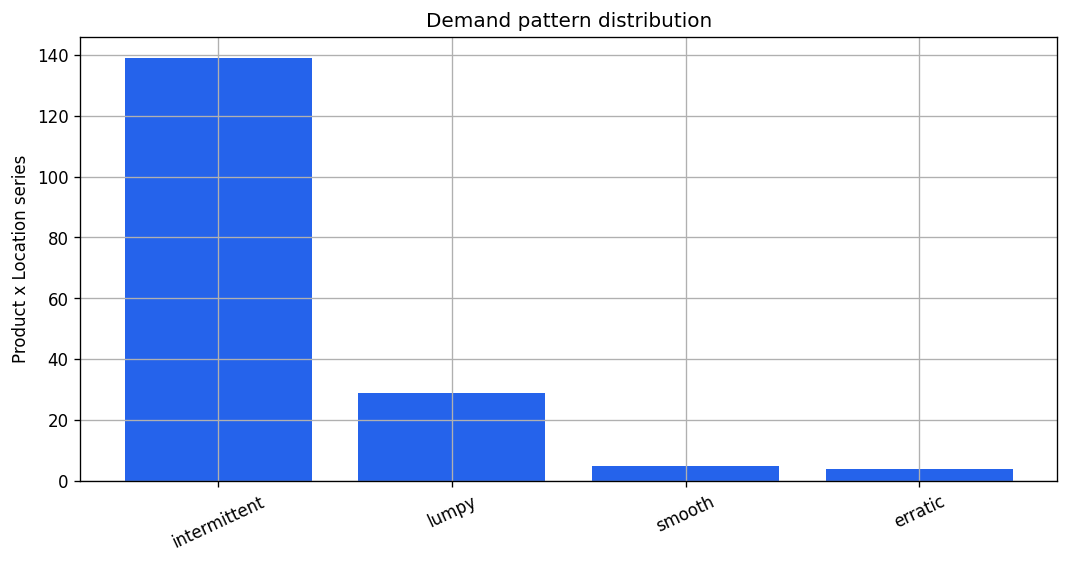

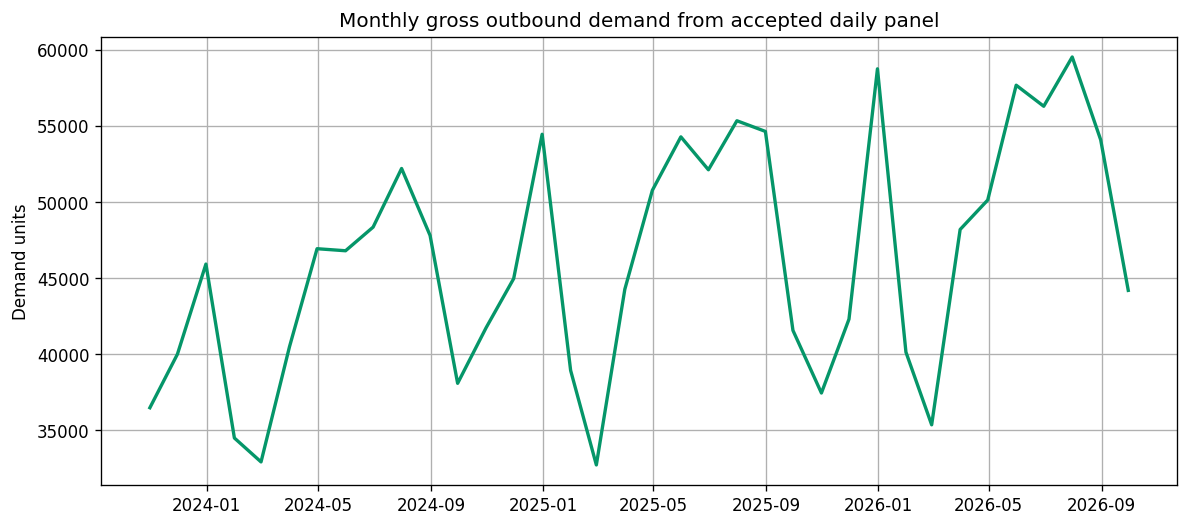

,Product_ID,Location_ID,Product_Name,Location_Name,Channel,Total_Demand,Zero_Demand_Pct,Demand_Pattern_Class,May_Need_Fallback_Later
152,P051,LOC003,Ice cream - بيجامة حريمي صيفي2024,El-Sharnouby Wholesale Desk,Wholesale,63456.0,22.536496,smooth,False
2,P001,LOC003,Summer children's girls-Happy,El-Sharnouby Wholesale Desk,Wholesale,60438.0,24.726277,lumpy,True
23,P008,LOC003,Summer children's boys-SpongeBob,El-Sharnouby Wholesale Desk,Wholesale,57048.0,26.007326,intermittent,True
110,P037,LOC003,Girls' sweatshirt-Flower,El-Sharnouby Wholesale Desk,Wholesale,53076.0,39.669421,intermittent,True
86,P029,LOC003,Girls' pajamas-Daylife+kuromi,El-Sharnouby Wholesale Desk,Wholesale,41724.0,33.485819,intermittent,True
176,P059,LOC003,Positive vibes - 2024بيجامة حريمي صيفي,El-Sharnouby Wholesale Desk,Wholesale,38256.0,36.438356,intermittent,True
98,P033,LOC003,Boys' sweatshirt-LEO,El-Sharnouby Wholesale Desk,Wholesale,38232.0,47.889908,lumpy,True
41,P014,LOC003,Boys' summer t-shirt-Black,El-Sharnouby Wholesale Desk,Wholesale,36066.0,38.138686,intermittent,True
113,P038,LOC003,Boys' Autumn Pajamas-Mickey Mouse,El-Sharnouby Wholesale Desk,Wholesale,35976.0,50.091241,intermittent,True
116,P039,LOC003,Boys' Autumn Pajamas-Spider Man,El-Sharnouby Wholesale Desk,Wholesale,34542.0,49.633028,intermittent,True


In [5]:
demand_eda = read_csv("outputs/phase2/demand_series_eda.csv")
daily_panel = read_csv("data/processed/daily_product_location_demand_panel.csv")

pattern_counts = demand_eda["Demand_Pattern_Class"].value_counts().reindex(["intermittent", "lumpy", "smooth", "erratic"]).fillna(0).astype(int)
simple_bar(pattern_counts.index.tolist(), pattern_counts.values.tolist(), "Demand pattern distribution", ylabel="Product x Location series", color="#2563eb")

daily_panel["Date"] = pd.to_datetime(daily_panel["Date"])
monthly_demand = daily_panel.groupby(pd.Grouper(key="Date", freq="ME"))["Demand_Units"].sum().reset_index()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(monthly_demand["Date"], monthly_demand["Demand_Units"], color="#059669", linewidth=2)
ax.set_title("Monthly gross outbound demand from accepted daily panel")
ax.set_ylabel("Demand units")
plt.tight_layout()
plt.show()

show_table(demand_eda.sort_values("Total_Demand", ascending=False), ["Product_ID", "Location_ID", "Product_Name", "Location_Name", "Channel", "Total_Demand", "Zero_Demand_Pct", "Demand_Pattern_Class", "May_Need_Fallback_Later"], n=10)


## 6. Inventory and Reconciliation

The monthly finished-goods inventory accounting identity was validated in Phase 2:

Closing_Stock = Opening_Stock + Received_Qty + Returned_Qty - Sold_Qty - Damaged_Qty

The identity matched 6,225 of 6,372 inventory rows. The remaining 147 mismatches were documented and not forcibly corrected.

Monthly Sales_Transactions.Quantity reconciled exactly to Inventory_History.Sold_Qty for all 6,372 month/product/location rows. This supports using gross outbound demand from Sales_Transactions.Quantity as the forecasting target.

Returns were material but not dominant: 8,543 returned rows, 37,233 returned units, and returns equal to 2.242% of sold quantity.


Inventory accounting summary
Sales vs inventory reconciliation summary
Returns summary


,metric,value
0,rows_checked,6372.000000
1,rows_holding_exactly,6225.000000
2,rows_holding_exactly_pct,97.693032
3,mismatch_rows,147.000000
4,mismatch_rows_pct,2.306968
5,mismatch_min,1.000000
6,mismatch_median,47.000000
7,mismatch_mean,106.829932
8,mismatch_p90,183.000000
9,mismatch_p95,244.200000


,metric,value
0,rows_compared,6372.0
1,rows_with_both_sources,6353.0
2,rows_inventory_only_after_zero_fill,19.0
3,rows_sales_only,0.0
4,exact_match_rows,6372.0
5,exact_match_pct_all_rows,100.0
6,exact_match_pct_rows_with_both_sources,100.0
7,absolute_difference_mean,0.0
8,absolute_difference_median,0.0
9,absolute_difference_p95,0.0


,metric,value
0,sales_rows,180000
1,returned_rows,8543
2,returned_rows_pct,4.746111111111111
3,quantity_total,1660589.0
4,returned_quantity_by_order_date,37233.0
5,returned_quantity_pct_of_sales_quantity,2.2421562469702017
6,refund_value_total_egp,9427005.55
7,return_date_present_for_returned_rows_pct,100.0
8,return_lag_days_median,11.0
9,return_lag_days_p95,20.0


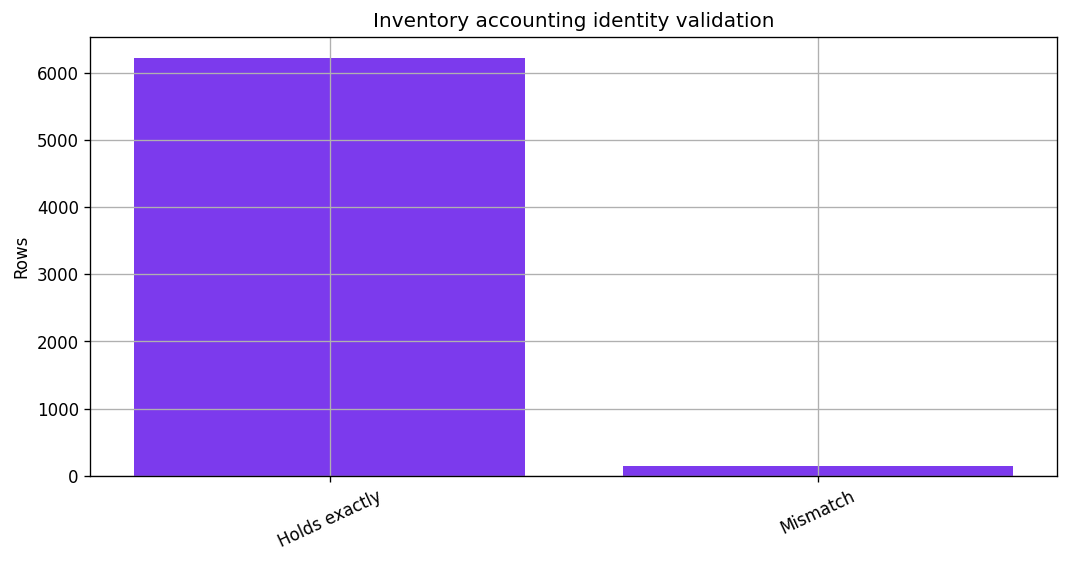

In [6]:
accounting_summary = read_csv("outputs/phase2/inventory_accounting_summary.csv")
sales_inventory_recon = read_csv("outputs/phase2/sales_inventory_reconciliation_summary.csv")
returns_summary = read_csv("outputs/phase2/returns_summary.csv")

print("Inventory accounting summary")
display(accounting_summary)
print("Sales vs inventory reconciliation summary")
display(sales_inventory_recon)
print("Returns summary")
display(returns_summary)

mismatch_rows = read_csv("outputs/phase2/inventory_accounting_validation.csv")
holds = mismatch_rows["Accounting_Holds_Exactly"].value_counts().rename(index={True: "Holds exactly", False: "Mismatch"})
simple_bar(holds.index.astype(str).tolist(), holds.values.tolist(), "Inventory accounting identity validation", ylabel="Rows", color="#7c3aed")


## 7. Forecasting Method

The accepted forecasting grain is Product_ID x Location_ID. The accepted horizons are 30, 60, and 90 days. Rolling-origin validation used these origins:

- 2025-09-28
- 2025-12-28
- 2026-03-29
- 2026-06-28

The best overall baseline was weekly_distributed / weekly_seasonal_naive_52w. Advanced models were compared, but the final policy was guarded: advanced selections were accepted only when validation evidence supported them. Otherwise, the policy fell back to the transparent weekly seasonal baseline.

Leakage controls came from Phase 2. Realized transaction outcomes, returns outcomes, and future inventory/decision fields are not allowed as forecasting features.


In [7]:
validation_folds = read_csv("outputs/phase3/validation_fold_summary.csv")
leakage_table = read_csv("outputs/phase2/leakage_risk_table.csv")

show_table(validation_folds, n=10)
display(leakage_table)


,Product_ID,Location_ID,Fold_ID,Forecast_Origin,Training_Start,Training_End,Forecast_Start,Forecast_End,Horizon_Days,Training_Days,Validation_Days,Has_Full_Validation_Window,No_Train_Test_Overlap,Forecast_Dates_After_Training,Fold_Status
0,P001,LOC001,1,2025-09-28,2023-10-01,2025-09-28,2025-09-29,2025-10-28,30,729,30,True,True,True,baseline_evaluated_normally
1,P001,LOC001,1,2025-09-28,2023-10-01,2025-09-28,2025-09-29,2025-11-27,60,729,60,True,True,True,baseline_evaluated_normally
2,P001,LOC001,1,2025-09-28,2023-10-01,2025-09-28,2025-09-29,2025-12-27,90,729,90,True,True,True,baseline_evaluated_normally
3,P001,LOC001,2,2025-12-28,2023-10-01,2025-12-28,2025-12-29,2026-01-27,30,820,30,True,True,True,baseline_evaluated_normally
4,P001,LOC001,2,2025-12-28,2023-10-01,2025-12-28,2025-12-29,2026-02-26,60,820,60,True,True,True,baseline_evaluated_normally
5,P001,LOC001,2,2025-12-28,2023-10-01,2025-12-28,2025-12-29,2026-03-28,90,820,90,True,True,True,baseline_evaluated_normally
6,P001,LOC001,3,2026-03-29,2023-10-01,2026-03-29,2026-03-30,2026-04-28,30,911,30,True,True,True,baseline_evaluated_normally
7,P001,LOC001,3,2026-03-29,2023-10-01,2026-03-29,2026-03-30,2026-05-28,60,911,60,True,True,True,baseline_evaluated_normally
8,P001,LOC001,3,2026-03-29,2023-10-01,2026-03-29,2026-03-30,2026-06-27,90,911,90,True,True,True,baseline_evaluated_normally
9,P001,LOC001,4,2026-06-28,2023-10-01,2026-06-28,2026-06-29,2026-07-28,30,1002,30,True,True,True,baseline_evaluated_normally


,table,column_or_group,leakage_risk,safe_use_rule
0,Sales_Transactions,Quantity,Target,Use only as the demand target after aggregatio...
1,Sales_Transactions,"Gross_Sales_EGP, Net_Sales_EGP, Estimated_COGS...",High,These are realized transaction outcomes that i...
2,Sales_Transactions,"Returned, Return_Date, Return_Reason, Refund_V...",High,Return outcomes happen after the sale and are ...
3,Sales_Transactions,"Invoice_ID, Row_ID, Customer_ID, Payment_Method",Medium,Transaction-specific identifiers or choices ar...
4,Sales_Transactions,"Discount_Pct, List_Price_EGP",Conditional,Only safe if known in advance as planned comme...
5,Inventory_History,"Sold_Qty, Closing_Stock, Days_of_Cover, Stocko...",High,These period-end inventory outcomes encode rea...
6,Inventory_History,"Opening_Stock, Safety_Stock_Units, Reorder_Poi...",Conditional,Only safe as lagged features if available befo...
7,Purchase_Orders,"Actual_Receipt_Date, Accepted_Qty, Rejected_Qty",High for demand forecasting,Procurement outcomes occur after order placeme...
8,Production_Orders,"Completion_Date, Produced_Qty, Good_Qty, Rejec...",High for demand forecasting,Production outcomes can be analyzed historical...


## 8. Forecast Model Validation

Accepted validation story:

- Baseline weekly_seasonal_naive_52w cumulative WAPE: 22.251%.
- Apparent per-series selected-policy WAPE: 17.071%, but this is optimistic because selection and scoring used the same folds.
- Honest leave-one-fold-out WAPE: 27.464%.
- Final guarded hybrid equal-coverage WAPE: 20.196%.

The final policy is therefore a guarded hybrid, not simply the most complex model or the apparent winner. The selected policy balances accuracy evidence with robustness.


,Policy,Accepted WAPE %,Interpretation
0,Baseline weekly_seasonal_naive_52w,22.250733,Transparent best baseline
1,Apparent per-series selected policy,17.070660,Optimistic same-fold selection/scoring
2,Leave-one-fold-out policy,27.464146,Honest robustness check
3,Final guarded hybrid,20.195557,Accepted fair equal-coverage validation


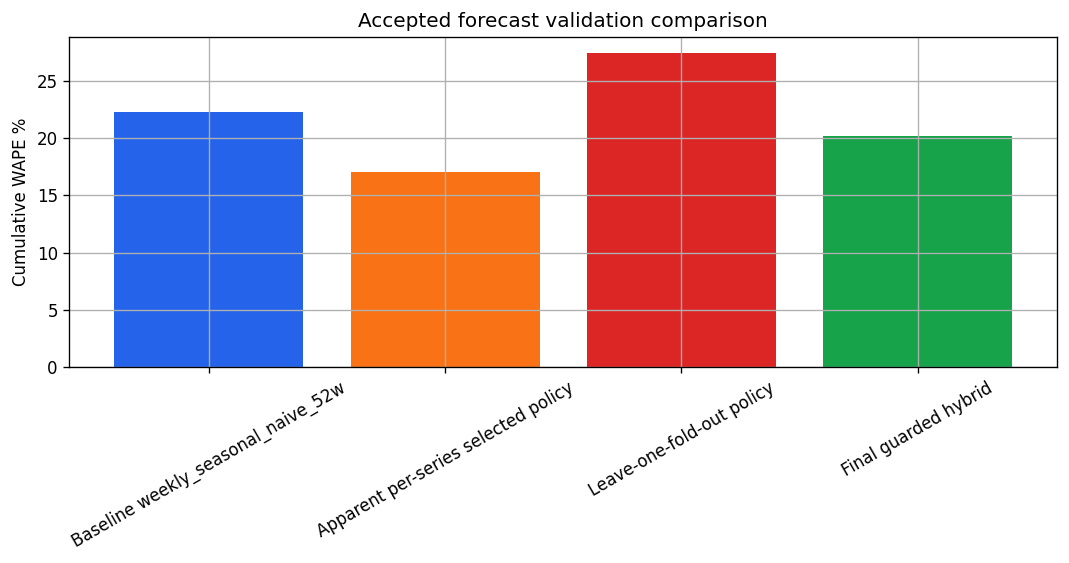

In [8]:
baseline_metrics = read_csv("outputs/phase3/baseline_metrics_overall.csv")
policy_comparison = read_csv("outputs/phase4_1/policy_comparison.csv")
lofo_metrics = read_csv("outputs/phase4_1/leave_one_fold_out_policy_metrics.csv")
full_coverage = read_csv("outputs/phase5_1/full_coverage_policy_comparison.csv")

baseline_wape = baseline_metrics.loc[
    (baseline_metrics["Frequency"] == "weekly_distributed") &
    (baseline_metrics["Baseline"] == "weekly_seasonal_naive_52w"),
    "Cumulative_WAPE",
].iloc[0]
apparent_wape = policy_comparison.loc[
    (policy_comparison["Policy"] == "phase4_apparent_selection") &
    (policy_comparison["Segment_Type"] == "overall"),
    "Cumulative_WAPE",
].iloc[0]
lofo_wape = lofo_metrics.loc[
    (lofo_metrics["Policy"] == "leave_one_fold_out_selection") &
    (lofo_metrics["Segment_Type"] == "overall"),
    "Cumulative_WAPE",
].iloc[0]
guarded_wape = full_coverage.loc[
    (full_coverage["Policy"] == "guarded_hybrid") &
    (full_coverage["Segment_Type"] == "overall"),
    "Cumulative_WAPE",
].iloc[0]

validation_story = pd.DataFrame([
    {"Policy": "Baseline weekly_seasonal_naive_52w", "Accepted WAPE %": baseline_wape, "Interpretation": "Transparent best baseline"},
    {"Policy": "Apparent per-series selected policy", "Accepted WAPE %": apparent_wape, "Interpretation": "Optimistic same-fold selection/scoring"},
    {"Policy": "Leave-one-fold-out policy", "Accepted WAPE %": lofo_wape, "Interpretation": "Honest robustness check"},
    {"Policy": "Final guarded hybrid", "Accepted WAPE %": guarded_wape, "Interpretation": "Accepted fair equal-coverage validation"},
])
display(validation_story)

fig, ax = plt.subplots()
ax.bar(validation_story["Policy"], validation_story["Accepted WAPE %"], color=["#2563eb", "#f97316", "#dc2626", "#16a34a"])
ax.set_title("Accepted forecast validation comparison")
ax.set_ylabel("Cumulative WAPE %")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


## 9. Final Forecast

The accepted future forecast output contains 531 rows: 177 Product x Location series across 30, 60, and 90 days. The forecast origin is 2026-09-30, the forecast starts on 2026-10-01, and the accepted forecast windows end on 2026-10-30, 2026-11-29, and 2026-12-29.

Coverage is complete for all 177 Product x Location series. The final selected sources were 69 guarded advanced selections and 462 baseline selections. This notebook does not regenerate predictions.


,Metric,Accepted value
0,Forecast rows,531
1,Product x Location pairs,177
2,Products,59
3,Locations,3


,Horizon_Days,Rows
0,30,177
1,60,177
2,90,177


,Selected_Model_Source,Rows
0,baseline,462
1,advanced,69


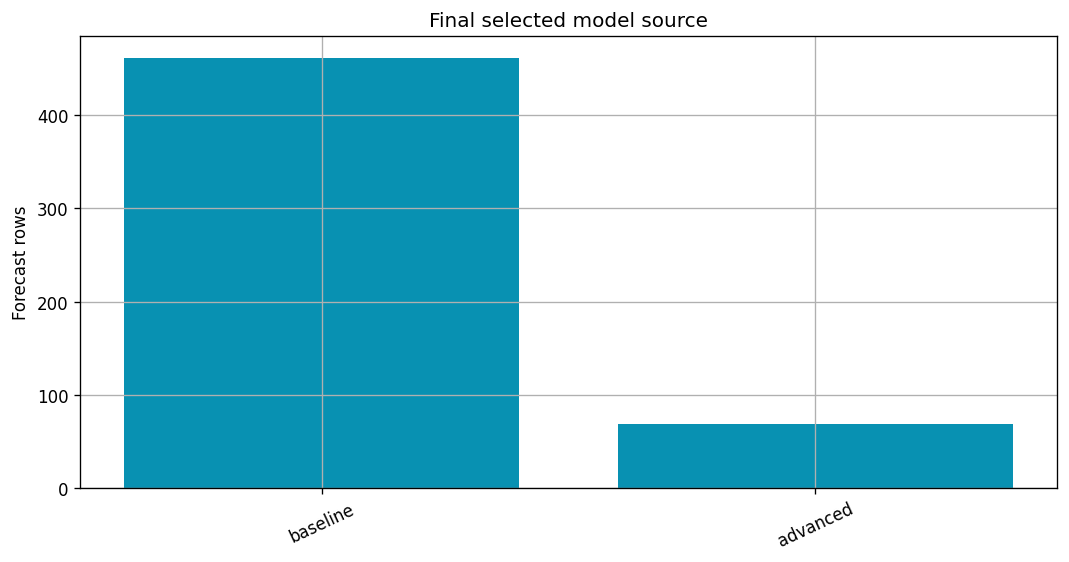

,Product_ID,Product_Name,Location_ID,Location_Name,Channel,Horizon_Days,Forecast_Demand,Selected_Model,Selected_Model_Source
332,P037,Girls' sweatshirt-Flower,LOC003,El-Sharnouby Wholesale Desk,Wholesale,90,9732.857143,weekly_seasonal_naive_52w,baseline
296,P033,Boys' sweatshirt-LEO,LOC003,El-Sharnouby Wholesale Desk,Wholesale,90,6725.142857,weekly_seasonal_naive_52w,baseline
341,P038,Boys' Autumn Pajamas-Mickey Mouse,LOC003,El-Sharnouby Wholesale Desk,Wholesale,90,6560.571429,weekly_seasonal_naive_52w,baseline
331,P037,Girls' sweatshirt-Flower,LOC003,El-Sharnouby Wholesale Desk,Wholesale,60,6312.857143,weekly_seasonal_naive_52w,baseline
287,P032,Boys' sweatshirt-blue,LOC003,El-Sharnouby Wholesale Desk,Wholesale,90,6090.857143,weekly_seasonal_naive_52w,baseline
350,P039,Boys' Autumn Pajamas-Spider Man,LOC003,El-Sharnouby Wholesale Desk,Wholesale,90,5949.428571,weekly_seasonal_naive_52w,baseline
386,P043,Girls' autumn pajamas-Snow White,LOC003,El-Sharnouby Wholesale Desk,Wholesale,90,5749.714286,weekly_seasonal_naive_52w,baseline
404,P045,Girls' autumn pajamas-Stitch,LOC003,El-Sharnouby Wholesale Desk,Wholesale,90,5509.714286,weekly_seasonal_naive_52w,baseline
395,P044,Girls' autumn pajamas-Ice Cream,LOC003,El-Sharnouby Wholesale Desk,Wholesale,90,5184.857143,weekly_seasonal_naive_52w,baseline
349,P039,Boys' Autumn Pajamas-Spider Man,LOC003,El-Sharnouby Wholesale Desk,Wholesale,60,3473.142857,weekly_seasonal_naive_52w,baseline


In [9]:
forecast = read_csv("outputs/phase5/forecast_results.csv")
coverage = pd.DataFrame({
    "Metric": ["Forecast rows", "Product x Location pairs", "Products", "Locations"],
    "Accepted value": [len(forecast), forecast[["Product_ID", "Location_ID"]].drop_duplicates().shape[0], forecast["Product_ID"].nunique(), forecast["Location_ID"].nunique()],
})
display(coverage)

display(forecast["Horizon_Days"].value_counts().sort_index().rename_axis("Horizon_Days").reset_index(name="Rows"))
source_counts = forecast["Selected_Model_Source"].value_counts().rename_axis("Selected_Model_Source").reset_index(name="Rows")
display(source_counts)
simple_bar(source_counts["Selected_Model_Source"].astype(str).tolist(), source_counts["Rows"].tolist(), "Final selected model source", ylabel="Forecast rows", color="#0891b2")

show_table(forecast.sort_values("Forecast_Demand", ascending=False), ["Product_ID", "Product_Name", "Location_ID", "Location_Name", "Channel", "Horizon_Days", "Forecast_Demand", "Selected_Model", "Selected_Model_Source"], n=10)


## 10. Inventory / Stockout Risk

The latest finished-goods inventory snapshot is September 2026 and contains 177 latest Product x Location rows. No negative latest finished-goods stock was found.

For the 90-day horizon:

- High inventory risk: 85 rows.
- Medium inventory risk: 0 rows.
- Low inventory risk: 92 rows.
- Expected shortage: 106,723.191 units.

Finished-goods stock is distinct from raw-material stock. The project has finished-goods inventory history, but no raw-material inventory table.


,Inventory_Risk,Rows
0,High,85
1,Medium,0
2,Low,92


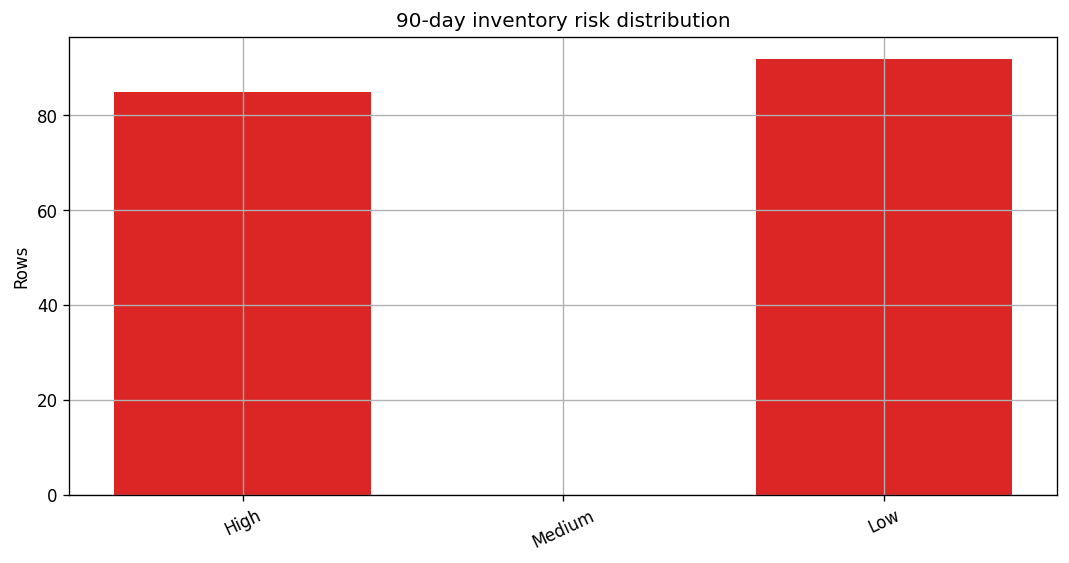

,Metric,Accepted value
0,90-day expected shortage,106723.191441
1,90-day recommended finished-goods replenishment,117853.191441
2,Rows with expected shortage,85.000000


,Product_ID,Product_Name,Location_ID,Location_Name,Forecast_Demand,Available_Stock,Expected_Shortage_Units,Recommended_Replenishment_Qty,Estimated_Stockout_Date,Inventory_Risk,Inventory_Risk_Reason
332,P037,Girls' sweatshirt-Flower,LOC003,El-Sharnouby Wholesale Desk,9732.857143,2014,7718.857143,7893.857143,2026-10-23,High,forecast demand exceeds available stock by 771...
296,P033,Boys' sweatshirt-LEO,LOC003,El-Sharnouby Wholesale Desk,6725.142857,45,6680.142857,6729.142857,2026-10-01,High,forecast demand exceeds available stock by 668...
341,P038,Boys' Autumn Pajamas-Mickey Mouse,LOC003,El-Sharnouby Wholesale Desk,6560.571429,56,6504.571429,6538.571429,2026-10-05,High,forecast demand exceeds available stock by 650...
350,P039,Boys' Autumn Pajamas-Spider Man,LOC003,El-Sharnouby Wholesale Desk,5949.428571,258,5691.428571,5862.428571,2026-10-09,High,forecast demand exceeds available stock by 569...
386,P043,Girls' autumn pajamas-Snow White,LOC003,El-Sharnouby Wholesale Desk,5749.714286,61,5688.714286,5755.714286,2026-10-02,High,forecast demand exceeds available stock by 568...
287,P032,Boys' sweatshirt-blue,LOC003,El-Sharnouby Wholesale Desk,6090.857143,687,5403.857143,5501.857143,2026-10-14,High,forecast demand exceeds available stock by 540...
404,P045,Girls' autumn pajamas-Stitch,LOC003,El-Sharnouby Wholesale Desk,5509.714286,207,5302.714286,5391.714286,2026-10-06,High,forecast demand exceeds available stock by 530...
395,P044,Girls' autumn pajamas-Ice Cream,LOC003,El-Sharnouby Wholesale Desk,5184.857143,0,5184.857143,5258.857143,2026-10-01,High,forecast demand exceeds available stock by 518...
314,P035,Girls' sweatshirt-Fuchsia,LOC003,El-Sharnouby Wholesale Desk,3191.142857,143,3048.142857,3081.142857,2026-10-06,High,forecast demand exceeds available stock by 304...
323,P036,Girls' sweatshirt-Tinker Bell,LOC003,El-Sharnouby Wholesale Desk,3030.000000,234,2796.000000,2838.000000,2026-10-09,High,forecast demand exceeds available stock by 279...


In [10]:
stockout = read_csv("outputs/phase5/stockout_analysis.csv")
stockout_90 = stockout[stockout["Horizon_Days"] == 90].copy()
risk_counts = stockout_90["Inventory_Risk"].value_counts().reindex(["High", "Medium", "Low"]).fillna(0).astype(int)
display(risk_counts.rename_axis("Inventory_Risk").reset_index(name="Rows"))
simple_bar(risk_counts.index.tolist(), risk_counts.values.tolist(), "90-day inventory risk distribution", ylabel="Rows", color="#dc2626")

inventory_kpis = pd.DataFrame([
    {"Metric": "90-day expected shortage", "Accepted value": stockout_90["Expected_Shortage_Units"].sum()},
    {"Metric": "90-day recommended finished-goods replenishment", "Accepted value": stockout_90["Recommended_Replenishment_Qty"].sum()},
    {"Metric": "Rows with expected shortage", "Accepted value": int((stockout_90["Expected_Shortage_Units"] > 0).sum())},
])
display(inventory_kpis)
show_table(stockout_90.sort_values("Expected_Shortage_Units", ascending=False), ["Product_ID", "Product_Name", "Location_ID", "Location_Name", "Forecast_Demand", "Available_Stock", "Expected_Shortage_Units", "Recommended_Replenishment_Qty", "Estimated_Stockout_Date", "Inventory_Risk", "Inventory_Risk_Reason"], n=10)


## 11. Finished-Goods Replenishment

Recommended_Replenishment_Qty is a finished-goods planning quantity. It is not a confirmed production quantity.

Accepted production-equivalent replenishment totals:

- 30 days: 27,501.377 units.
- 60 days: 63,247.065 units.
- 90 days: 117,853.191 units.

Products requiring replenishment are 45 at 30 days, 54 at 60 days, and 55 at 90 days.


,Horizon_Days,Products_Requiring_Replenishment,Production_Equivalent_Replenishment_Qty
0,30,45,27501.377094
1,60,54,63247.065455
2,90,55,117853.191441


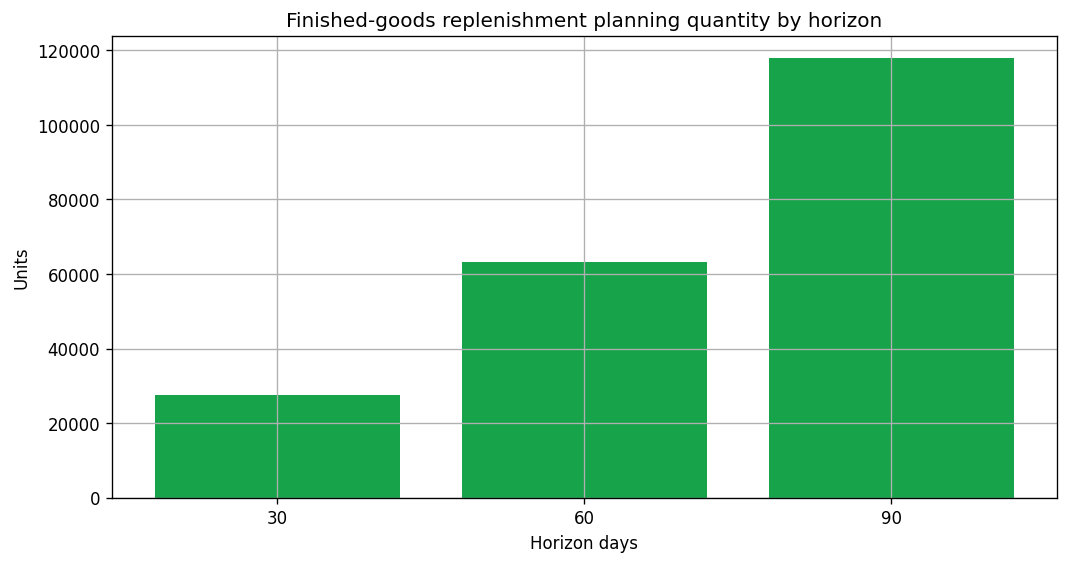

In [11]:
product_replenishment = read_csv("outputs/phase6/product_replenishment_requirements.csv")
replenishment_by_horizon = product_replenishment.groupby("Horizon_Days", as_index=False).agg(
    Products_Requiring_Replenishment=("Requires_Replenishment", "sum"),
    Production_Equivalent_Replenishment_Qty=("Production_Equivalent_Replenishment_Qty", "sum"),
)
display(replenishment_by_horizon)

fig, ax = plt.subplots()
ax.bar(replenishment_by_horizon["Horizon_Days"].astype(str), replenishment_by_horizon["Production_Equivalent_Replenishment_Qty"], color="#16a34a")
ax.set_title("Finished-goods replenishment planning quantity by horizon")
ax.set_xlabel("Horizon days")
ax.set_ylabel("Units")
plt.tight_layout()
plt.show()


## 12. BOM / Material Requirements

All replenishment products have BOM coverage in the accepted Phase 6 outputs. Product x Location material requirements reconcile within numerical tolerance.

Material quantities are gross material requirements conditional on producing the replenishment quantities. They are not net requirements and not purchase quantities because the project has no raw-material inventory table. Current raw-material stock and material shortages cannot be calculated from the provided data.


BOM coverage validation
Material requirement reconciliation


,Product_ID,Product_Name,Product_Family,Horizon_Days,Production_Equivalent_Replenishment_Qty,Locations_Requiring_Replenishment_Count,High_Risk_Locations_Count,Requires_Replenishment,BOM_Row_Count,Duplicate_Product_Material_Rows,Unresolved_BOM_Material_Count,Non_Numeric_Required_Per_Unit_Count,Negative_Required_Per_Unit_Count,Missing_Unit_Count,Unit_Mismatch_Count,Has_BOM_Coverage,Missing_BOM_Flag,BOM_Coverage_Status
0,P001,Summer children's girls-Happy,Pajamas/Homewear,30,812.000000,3,2,True,5,0,0,0,0,0,0,True,False,covered_replenishment_product
1,P001,Summer children's girls-Happy,Pajamas/Homewear,60,1767.000000,3,3,True,5,0,0,0,0,0,0,True,False,covered_replenishment_product
2,P001,Summer children's girls-Happy,Pajamas/Homewear,90,2919.000000,3,3,True,5,0,0,0,0,0,0,True,False,covered_replenishment_product
3,P002,Summer children's girls-turtle,Pajamas/Homewear,30,812.347353,3,3,True,6,0,0,0,0,0,0,True,False,covered_replenishment_product
4,P002,Summer children's girls-turtle,Pajamas/Homewear,60,1189.141060,3,3,True,6,0,0,0,0,0,0,True,False,covered_replenishment_product
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172,P058,OHANA - بيجامة حريمي صيفي 2024,Pajamas/Homewear,60,474.000000,1,1,True,5,0,0,0,0,0,0,True,False,covered_replenishment_product
173,P058,OHANA - بيجامة حريمي صيفي 2024,Pajamas/Homewear,90,1198.848381,1,1,True,5,0,0,0,0,0,0,True,False,covered_replenishment_product
174,P059,Positive vibes - 2024بيجامة حريمي صيفي,Pajamas/Homewear,30,173.000000,1,0,True,6,0,0,0,0,0,0,True,False,covered_replenishment_product
175,P059,Positive vibes - 2024بيجامة حريمي صيفي,Pajamas/Homewear,60,1123.522053,1,1,True,6,0,0,0,0,0,0,True,False,covered_replenishment_product


,Product_ID,Material_ID,Horizon_Days,Unit,Product_Level_Gross_Material_Requirement,Location_Level_Material_Requirement_Sum,Difference,Absolute_Difference,Reconciliation_Passed
0,P001,M001,30,meter,844.480,844.480,1.136868e-13,1.136868e-13,True
1,P001,M001,60,meter,1837.680,1837.680,-2.273737e-13,2.273737e-13,True
2,P001,M001,90,meter,3035.760,3035.760,0.000000e+00,0.000000e+00,True
3,P001,M006,30,cone,25.984,25.984,0.000000e+00,0.000000e+00,True
4,P001,M006,60,cone,56.544,56.544,-7.105427e-15,7.105427e-15,True
5,P001,M006,90,cone,93.408,93.408,1.421085e-14,1.421085e-14,True
6,P001,M007,30,piece,812.000,812.000,0.000000e+00,0.000000e+00,True
7,P001,M007,60,piece,1767.000,1767.000,0.000000e+00,0.000000e+00,True
8,P001,M007,90,piece,2919.000,2919.000,0.000000e+00,0.000000e+00,True
9,P001,M008,30,piece,812.000,812.000,0.000000e+00,0.000000e+00,True


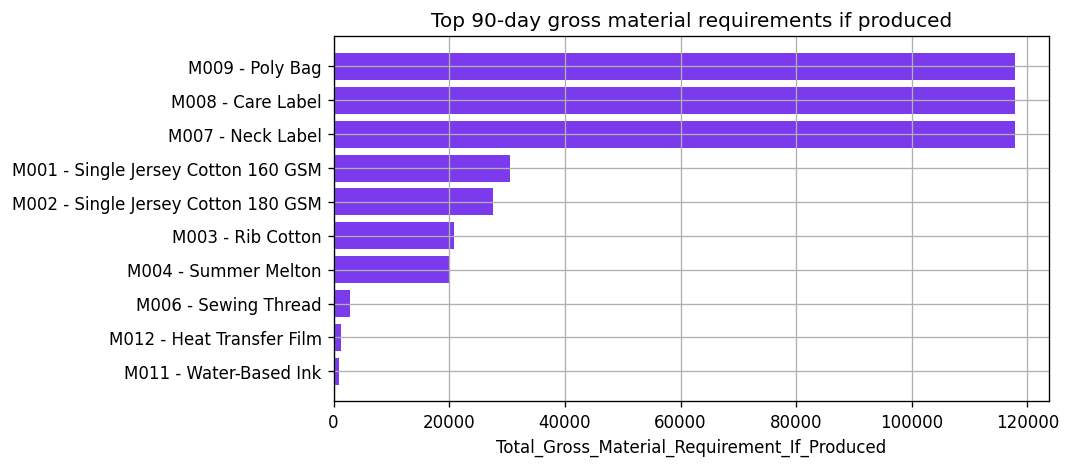

,Material_ID,Material_Name,Material_Category,Unit,Products_Requiring_Material_Count,Total_Gross_Material_Requirement_If_Produced
17,M007,Neck Label,Trims,piece,55,117853.191441
20,M008,Care Label,Trims,piece,55,117853.191441
23,M009,Poly Bag,Packaging,piece,55,117853.191441
2,M001,Single Jersey Cotton 160 GSM,Fabric,meter,14,30562.840963
5,M002,Single Jersey Cotton 180 GSM,Fabric,meter,13,27608.022896
8,M003,Rib Cotton,Fabric,meter,15,20786.576828
11,M004,Summer Melton,Fabric,meter,13,20036.778666
14,M006,Sewing Thread,Trims,cone,55,2853.016877
29,M012,Heat Transfer Film,Printing,sheet,16,1353.017093
26,M011,Water-Based Ink,Printing,kg,23,1021.878878


In [12]:
material_summary = read_csv("outputs/phase6/material_requirements_summary.csv")
material_risk = read_csv("outputs/phase7/material_requirement_procurement_risk.csv")
bom_coverage = read_csv("outputs/phase6/bom_coverage_validation.csv")
material_reconciliation = read_csv("outputs/phase6/material_requirement_reconciliation.csv")

print("BOM coverage validation")
display(bom_coverage)
print("Material requirement reconciliation")
show_table(material_reconciliation, n=10)

material_90 = material_summary[material_summary["Horizon_Days"] == 90].copy()
material_90["Material"] = material_90["Material_ID"] + " - " + material_90["Material_Name"]
horizontal_bar(material_90, "Material", "Total_Gross_Material_Requirement_If_Produced", "Top 90-day gross material requirements if produced", n=10, color="#7c3aed")
show_table(material_90.sort_values("Total_Gross_Material_Requirement_If_Produced", ascending=False), ["Material_ID", "Material_Name", "Material_Category", "Unit", "Products_Requiring_Material_Count", "Total_Gross_Material_Requirement_If_Produced"], n=10)


## 13. Procurement Risk

Phase 7 used Purchase_Orders.csv history as relative historical procurement evidence. It does not guarantee future supplier performance.

Accepted procurement facts:

- PO rows: 3,600.
- Historical on-time rate: 65.4%.
- Historical late rate: 34.6%.
- Mean actual lead time: 12.31 days.
- P90 actual lead time: 21 days.
- Material historical procurement risk: 5 High, 1 Medium, and 6 Low materials.

Systemic finding: all 59 products have Product_Historical_Procurement_Risk = High under the accepted weakest-link rule because common BOM materials drive the result. This is a systemic/common-material exposure, not a modeling bug.


,Metric,Accepted value
0,PO rows,3600
1,Historical on-time rate,65.4%
2,Historical late rate,34.6%
3,Mean actual lead time days,12.31
4,P90 actual lead time days,21


,Historical_Procurement_Risk,Materials
0,High,5
1,Medium,1
2,Low,6


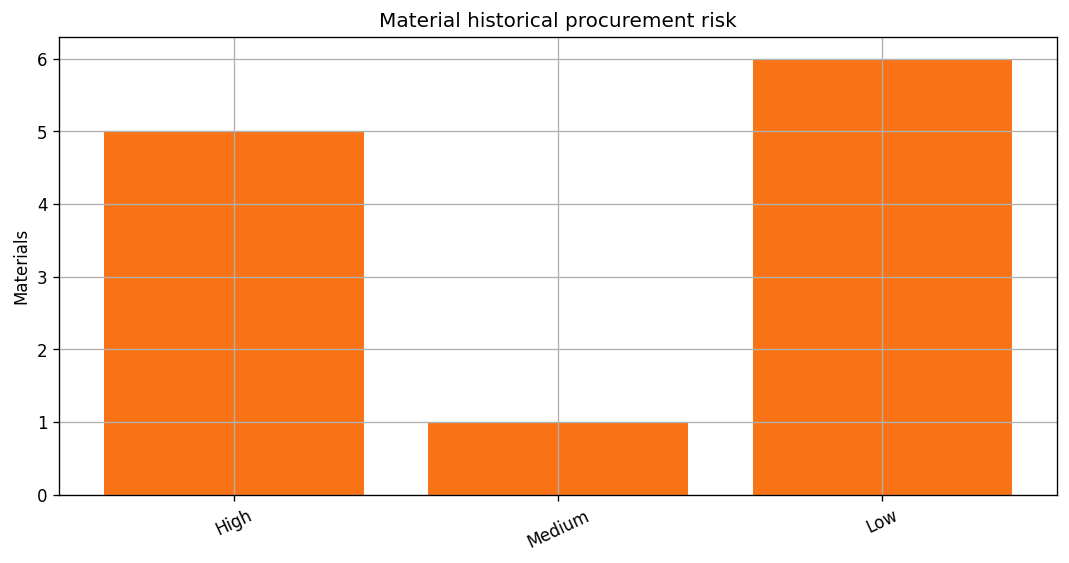

,Metric,Accepted value
0,90-day products with High product-level procur...,59


,Material_ID,Material_Name,PO_Count,Evidence_Level,Historical_Procurement_Risk,Procurement_Risk_Reason,Historical_P90_Actual_Lead_Time_Days,Late_PO_Rate,Mean_Rejection_Rate
3,M010,Carton Box,310,High,High,late PO rate 0.397 > empirical P90 0.387; mean...,21.0,0.396774,0.018145
2,M006,Sewing Thread,303,High,High,late PO rate 0.389 > empirical P90 0.387; mean...,21.0,0.389439,0.018006
1,M005,Elastic Band,279,High,High,mean rejection rate 0.019 > empirical P90 0.01...,21.0,0.344086,0.018533
4,M011,Water-Based Ink,286,High,High,mean delivery delay 1.119 > empirical P90 1.07...,21.0,0.332168,0.016557
0,M003,Rib Cotton,321,High,High,historical P90 actual lead time 22 > empirical...,22.0,0.327103,0.017019
7,M004,Summer Melton,286,High,Low,No monitored metric reached empirical P75 thre...,21.0,0.356643,0.018050
10,M009,Poly Bag,303,High,Low,No monitored metric reached empirical P75 thre...,21.0,0.349835,0.017345
5,M001,Single Jersey Cotton 160 GSM,286,High,Low,No monitored metric reached empirical P75 thre...,21.0,0.335664,0.017974
8,M007,Neck Label,290,High,Low,No monitored metric reached empirical P75 thre...,21.0,0.331034,0.017455
6,M002,Single Jersey Cotton 180 GSM,302,High,Low,No monitored metric reached empirical P75 thre...,21.0,0.314570,0.017142


In [13]:
proc_quality = read_csv("outputs/phase7/procurement_data_quality.csv")
historical_procurement = read_csv("outputs/phase7/historical_procurement_risk.csv")
product_procurement = read_csv("outputs/phase9/product_procurement_risk_summary.csv")

proc_summary = pd.DataFrame([
    {"Metric": "PO rows", "Accepted value": 3600},
    {"Metric": "Historical on-time rate", "Accepted value": "65.4%"},
    {"Metric": "Historical late rate", "Accepted value": "34.6%"},
    {"Metric": "Mean actual lead time days", "Accepted value": 12.31},
    {"Metric": "P90 actual lead time days", "Accepted value": 21},
])
display(proc_summary)

material_proc_risk_counts = historical_procurement["Historical_Procurement_Risk"].value_counts().reindex(["High", "Medium", "Low"]).fillna(0).astype(int)
display(material_proc_risk_counts.rename_axis("Historical_Procurement_Risk").reset_index(name="Materials"))
simple_bar(material_proc_risk_counts.index.tolist(), material_proc_risk_counts.values.tolist(), "Material historical procurement risk", ylabel="Materials", color="#f97316")

product_90 = product_procurement[product_procurement["Horizon_Days"] == 90]
systemic = product_90.groupby("Product_ID", as_index=False)["Product_Historical_Procurement_Risk"].max()
display(pd.DataFrame([{"Metric": "90-day products with High product-level procurement risk", "Accepted value": int((systemic["Product_Historical_Procurement_Risk"] == "High").sum())}]))
show_table(historical_procurement.sort_values(["Historical_Procurement_Risk", "Late_PO_Rate"], ascending=[True, False]), ["Material_ID", "Material_Name", "PO_Count", "Evidence_Level", "Historical_Procurement_Risk", "Procurement_Risk_Reason", "Historical_P90_Actual_Lead_Time_Days", "Late_PO_Rate", "Mean_Rejection_Rate"], n=12)


## 14. Production Risk

Phase 8 used Production_Orders.csv history as relative historical production evidence. It is not a future failure prediction.

Accepted production facts:

- Production orders: 2,500.
- Historical on-time production: 83.7%.
- Historical late production: 16.3%.
- Mean production lead time: 16.327 days.
- Median production lead time: 16 days.
- P90 production lead time: 24 days.
- Historical product production risk: 21 High, 15 Medium, 22 Low, and 1 Insufficient Evidence.
- Evidence levels: 45 High, 13 Medium, and 1 Low.

Future capacity, current line availability, and confirmed production schedules are unavailable.


,Metric,Accepted value
0,Production orders,2500
1,Historical on-time production,83.7%
2,Historical late production,16.3%
3,Mean production lead time days,16.327
4,Median production lead time days,16
5,P90 production lead time days,24


,Historical_Production_Risk,Products
0,High,21
1,Medium,15
2,Low,22
3,Insufficient Evidence,1


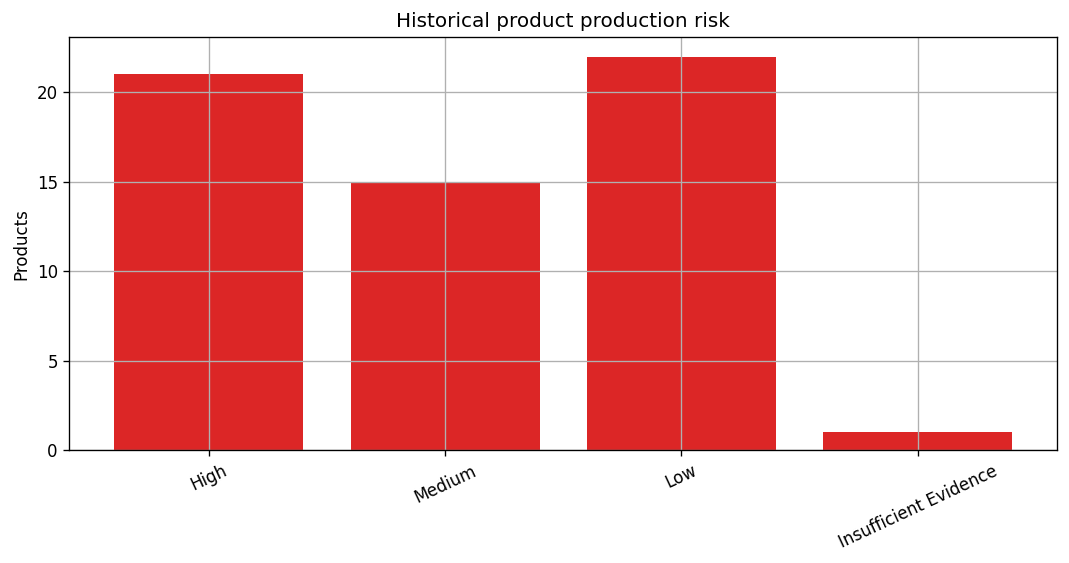

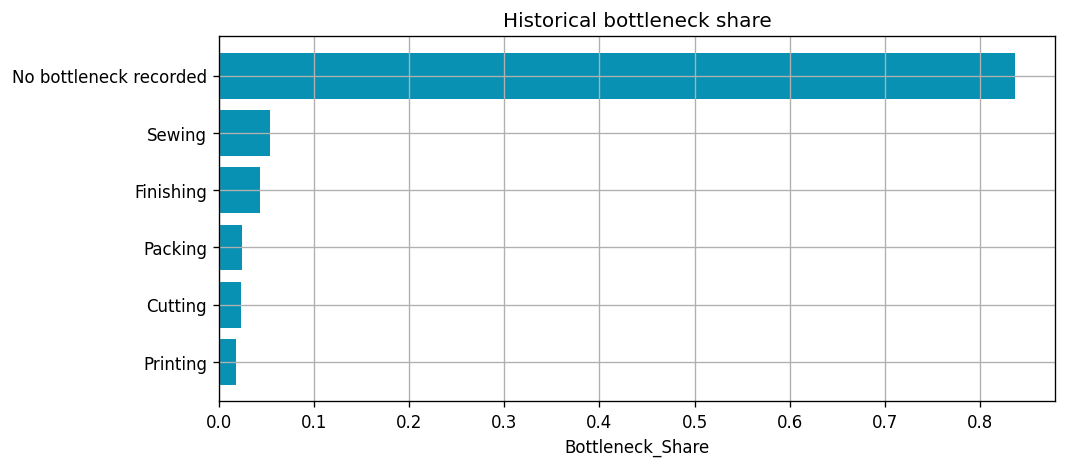

,Product_ID,Product_Name,Production_Order_Count,Production_Evidence_Level,Historical_Production_Risk,Production_Risk_Reason,P90_Production_Lead_Time_Days,Late_Production_Order_Rate,Mean_Efficiency_Pct
50,P051,Ice cream - بيجامة حريمي صيفي2024,117,High,Medium,late production order rate 0.197 > empirical P...,23.4,0.196581,81.601709
0,P001,Summer children's girls-Happy,114,High,Medium,late production order rate 0.211 > empirical P...,24.0,0.210526,82.713158
36,P037,Girls' sweatshirt-Flower,110,High,Medium,mean rejection rate 0.026 > empirical P75 0.02...,24.0,0.163636,82.558182
7,P008,Summer children's boys-SpongeBob,94,High,Medium,mean rejection rate 0.027 > empirical P75 0.02...,24.0,0.191489,82.380851
31,P032,Boys' sweatshirt-blue,77,High,Medium,late production order rate 0.234 > empirical P...,23.4,0.233766,83.133766
28,P029,Girls' pajamas-Daylife+kuromi,73,High,Low,No monitored metric crossed relative productio...,22.8,0.164384,81.921918
44,P045,Girls' autumn pajamas-Stitch,68,High,Low,No monitored metric crossed relative productio...,22.3,0.088235,83.039706
38,P039,Boys' Autumn Pajamas-Spider Man,68,High,Low,No monitored metric crossed relative productio...,23.0,0.176471,81.823529
58,P059,Positive vibes - 2024بيجامة حريمي صيفي,68,High,Low,No monitored metric crossed relative productio...,24.0,0.176471,82.680882
55,P056,BATGIRL - بيجامة حريمي صيفي2024,67,High,High,late production order rate 0.269 > empirical P...,25.4,0.268657,81.340299


In [14]:
production_quality = read_csv("outputs/phase8/production_data_quality.csv")
historical_production = read_csv("outputs/phase8/historical_production_risk.csv")
bottleneck = read_csv("outputs/phase8/bottleneck_analysis.csv")

prod_summary = pd.DataFrame([
    {"Metric": "Production orders", "Accepted value": 2500},
    {"Metric": "Historical on-time production", "Accepted value": "83.7%"},
    {"Metric": "Historical late production", "Accepted value": "16.3%"},
    {"Metric": "Mean production lead time days", "Accepted value": 16.327},
    {"Metric": "Median production lead time days", "Accepted value": 16},
    {"Metric": "P90 production lead time days", "Accepted value": 24},
])
display(prod_summary)

prod_risk_counts = historical_production["Historical_Production_Risk"].value_counts().reindex(["High", "Medium", "Low", "Insufficient Evidence"]).fillna(0).astype(int)
display(prod_risk_counts.rename_axis("Historical_Production_Risk").reset_index(name="Products"))
simple_bar(prod_risk_counts.index.tolist(), prod_risk_counts.values.tolist(), "Historical product production risk", ylabel="Products", color="#dc2626")

bottleneck_view = bottleneck.copy()
horizontal_bar(bottleneck_view, "Primary_Bottleneck", "Bottleneck_Share", "Historical bottleneck share", n=8, color="#0891b2")
show_table(historical_production.sort_values("Production_Order_Count", ascending=False), ["Product_ID", "Product_Name", "Production_Order_Count", "Production_Evidence_Level", "Historical_Production_Risk", "Production_Risk_Reason", "P90_Production_Lead_Time_Days", "Late_Production_Order_Rate", "Mean_Efficiency_Pct"], n=10)


## 15. Final Decision Logic

The Phase 9 decision layer combines inventory urgency with historical procurement and production evidence. Inventory urgency is primary. Procurement and production evidence can escalate operational difficulty, but they do not fabricate shortages.

Accepted Phase 9 outputs:

- Final decision table: 531 rows.
- All 177 Product x Location pairs retained.
- 90-day management priority: 177 rows.
- 90-day product cross-functional view: 59 rows.
- 90-day Decision_Risk: 85 High, 0 Medium, 92 Low.
- Conditional material action at/before forecast origin: 59 rows.
- Conditional production start at/before forecast origin: 40 rows.

Conditional action dates are planning estimates. They are not deadlines, confirmed purchase-order dates, or confirmed production start dates.


,Decision_Risk,Rows
0,High,85
1,Medium,0
2,Low,92


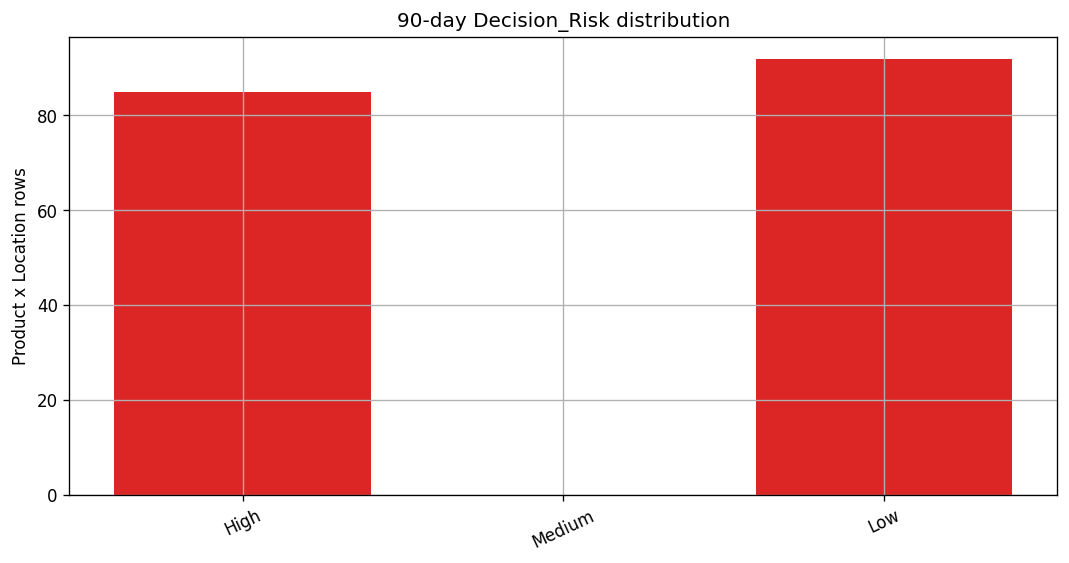

,Metric,Accepted value
0,Final decision rows,531
1,Product x Location pairs retained,177
2,90-day management priority rows,177
3,90-day product cross-functional rows,59
4,Conditional material action at/before origin,59
5,Conditional production start at/before origin,40


,Product_ID,Product_Name,Location_ID,Location_Name,Channel,Forecast_Demand,Available_Stock,Expected_Shortage_Units,Recommended_Replenishment_Qty,Inventory_Risk,Product_Historical_Procurement_Risk,Historical_Production_Risk,Decision_Risk,Recommended_Action
0,P033,Boys' sweatshirt-LEO,LOC003,El-Sharnouby Wholesale Desk,Wholesale,6725.142857,45,6680.142857,6729.142857,High,High,Low,High,Urgent cross-functional review: stockout expos...
1,P044,Girls' autumn pajamas-Ice Cream,LOC003,El-Sharnouby Wholesale Desk,Wholesale,5184.857143,0,5184.857143,5258.857143,High,High,Medium,High,Urgent cross-functional review: stockout expos...
2,P042,Girls' autumn pajamas-Cheeky Charmins,LOC003,El-Sharnouby Wholesale Desk,Wholesale,2191.714286,0,2191.714286,2222.714286,High,High,Low,High,Urgent cross-functional review: stockout expos...
3,P049,Fuchsia - طقم تيشيرت وشورت اطفال صيفي,LOC003,El-Sharnouby Wholesale Desk,Wholesale,1547.524757,0,1547.524757,1691.524757,High,High,High,High,Urgent cross-functional review: stockout expos...
4,P048,Semon - طقم تيشيرت وشورت اطفال صيفي,LOC003,El-Sharnouby Wholesale Desk,Wholesale,1476.857143,0,1476.857143,1620.857143,High,High,Medium,High,Urgent cross-functional review: stockout expos...
5,P004,Summer children's girls-Hello kitty black&white,LOC003,El-Sharnouby Wholesale Desk,Wholesale,1069.714286,0,1069.714286,1308.714286,High,High,Low,High,Urgent cross-functional review: stockout expos...
6,P002,Summer children's girls-turtle,LOC003,El-Sharnouby Wholesale Desk,Wholesale,1038.857143,0,1038.857143,1405.857143,High,High,Low,High,Urgent cross-functional review: stockout expos...
7,P006,Summer children's boys-Sonic,LOC003,El-Sharnouby Wholesale Desk,Wholesale,797.142857,2,795.142857,1105.142857,High,High,High,High,Urgent cross-functional review: stockout expos...
8,P002,Summer children's girls-turtle,LOC002,LEO MODA Online Store,Online,154.638273,0,154.638273,197.638273,High,High,Low,High,Urgent cross-functional review: stockout expos...
9,P043,Girls' autumn pajamas-Snow White,LOC003,El-Sharnouby Wholesale Desk,Wholesale,5749.714286,61,5688.714286,5755.714286,High,High,Medium,High,Urgent cross-functional review: stockout expos...


In [15]:
final_decision = read_csv("outputs/phase9/final_decision_recommendations.csv")
management_priority = read_csv("outputs/phase9/management_priority_90d.csv")
product_cross_functional = read_csv("outputs/phase9/product_cross_functional_90d.csv")
traceability = read_csv("outputs/phase9/decision_risk_traceability.csv")

final_90 = final_decision[final_decision["Horizon_Days"] == 90]
decision_counts = final_90["Decision_Risk"].value_counts().reindex(["High", "Medium", "Low"]).fillna(0).astype(int)
display(decision_counts.rename_axis("Decision_Risk").reset_index(name="Rows"))
simple_bar(decision_counts.index.tolist(), decision_counts.values.tolist(), "90-day Decision_Risk distribution", ylabel="Product x Location rows", color="#dc2626")

phase9_summary = pd.DataFrame([
    {"Metric": "Final decision rows", "Accepted value": len(final_decision)},
    {"Metric": "Product x Location pairs retained", "Accepted value": final_decision[["Product_ID", "Location_ID"]].drop_duplicates().shape[0]},
    {"Metric": "90-day management priority rows", "Accepted value": len(management_priority)},
    {"Metric": "90-day product cross-functional rows", "Accepted value": len(product_cross_functional)},
    {"Metric": "Conditional material action at/before origin", "Accepted value": int((final_90["Material_Action_Status"] == "At/Before forecast origin").sum())},
    {"Metric": "Conditional production start at/before origin", "Accepted value": int((final_90["Production_Action_Status"] == "At/Before forecast origin").sum())},
])
display(phase9_summary)

show_table(management_priority, ["Product_ID", "Product_Name", "Location_ID", "Location_Name", "Channel", "Forecast_Demand", "Available_Stock", "Expected_Shortage_Units", "Recommended_Replenishment_Qty", "Inventory_Risk", "Product_Historical_Procurement_Risk", "Historical_Production_Risk", "Decision_Risk", "Recommended_Action"], n=10)


## 16. Business Interpretation

The accepted analysis supports business discussion, not automatic execution.

Supported interpretations:

- Overforecast situation: if accepted forecast demand is materially above sales realization in a later review, increase marketing, offers, or channel activation before assuming production is the only lever.
- Underforecast situation: if actual demand outpaces accepted forecast or stockout exposure emerges, coordinate with factories to increase production quickly where feasible.
- Urgent stockout exposure: use the Phase 9 High Decision_Risk rows for cross-functional review across inventory, procurement, and production stakeholders.
- Material risk: review material-level historical procurement evidence, especially common BOM materials that drive weakest-link exposure.
- Production risk: review historical production lead-time, bottleneck, plan-attainment, efficiency, and rejection evidence before committing to timing.

The notebook does not recommend purchase orders, confirm production quantities, or schedule factory work.


## 17. Limitations

Major accepted limitations:

- No raw-material inventory table is available.
- Current raw-material stock cannot be calculated.
- Material requirements are gross requirements conditional on producing replenishment.
- Material requirements are not purchase quantities.
- Material shortages are not directly calculated.
- No future supplier availability is available.
- No confirmed purchase orders are modeled as future supply.
- No confirmed production schedule is available.
- No factory-capacity forecast is available.
- No current line availability is available.
- Historical procurement risk and historical production risk are historical relative-risk evidence, not future probability guarantees.
- conditional dates are planning estimates; the Phase 9 conditional action dates are not deadlines.
- Phase 2 inventory accounting produced 147 accounting mismatches; they remain documented and were not forcibly corrected.

These limitations are central to interpreting the decision layer responsibly.


## 18. Final Conclusions

The accepted project creates a complete, traceable planning view from historical demand and finished-goods inventory through forecast validation, stockout exposure, gross material requirements, historical procurement evidence, historical production evidence, and final cross-functional decision recommendations.

The final answer is not a single automated order plan. It is a management-support layer that shows where finished-goods shortages may occur, where replenishment planning is needed, and where historical procurement or production evidence suggests more operational coordination may be required.

The most important interpretation is disciplined separation:

- Forecasts are accepted model outputs.
- Replenishment is a finished-goods planning quantity.
- Material requirements are gross requirements if replenishment is produced.
- Procurement and production risks are historical relative evidence.
- Conditional dates are planning estimates.
- Missing raw-material inventory, future supplier availability, production schedules, and capacity information cannot be inferred.

The notebook therefore supports review, discussion, and next-step planning without inventing unsupported business facts.
